# CNN con Keras y MNIST - Comprender la arquitectura CNN y ajustar hiperparámetros básicos

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

In [2]:
# Cargar y preparar los datos
(x_train, y_train), (x_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
x_train = x_train.reshape(-1, 28, 28, 1).astype("float32") / 255
x_test = x_test.reshape(-1, 28, 28, 1).astype("float32") / 255
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

In [4]:
# Definición del modelo CNN
model = Sequential([
    Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, kernel_size=(3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [5]:
# Compilación del modelo
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [6]:
# Entrenamiento del modelo
history = model.fit(x_train, y_train, epochs=10, batch_size=128, validation_split=0.2)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - accuracy: 0.7701 - loss: 0.7207 - val_accuracy: 0.9784 - val_loss: 0.0722
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 39s 104ms/step - accuracy: 0.9674 - loss: 0.1123 - val_accuracy: 0.9838 - val_loss: 0.0542
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 38s 101ms/step - accuracy: 0.9755 - loss: 0.0782 - val_accuracy: 0.9870 - val_loss: 0.0453
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 40s 106ms/step - accuracy: 0.9817 - loss: 0.0618 - val_accuracy: 0.9884 - val_loss: 0.0403
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 39s 100ms/step - accuracy: 0.9844 - loss: 0.0513 - val_accuracy: 0.9892 - val_loss: 0.0391
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 100ms/step - accuracy: 0.9859 - loss: 0.0462 - val_accuracy: 0.9898 - val_loss: 0.0349
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 101ms/step - accuracy: 0.9886 - loss: 0.0401 - val_accuracy: 0.9898 - val_loss: 0.0366
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 101ms/step - accuracy: 0.9887 - loss: 0

In [7]:
# Evaluación del modelo
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"\n🔍 Precisión en test: {test_acc:.4f} - Pérdida: {test_loss:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9878 - loss: 0.0317

🔍 Precisión en test: 0.9907 - Pérdida: 0.0255


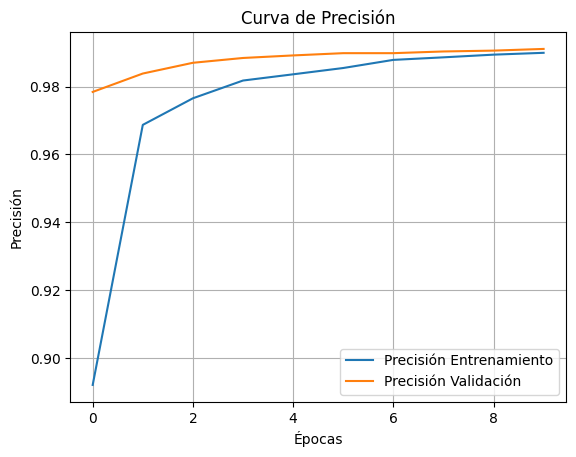

In [8]:
# Curvas de entrenamiento
plt.plot(history.history['accuracy'], label='Precisión Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Precisión Validación')
plt.xlabel('Épocas')
plt.ylabel('Precisión')
plt.legend()
plt.grid()
plt.title('Curva de Precisión')
plt.show()

In [9]:
# Tabla para registrar resultados
import pandas as pd

In [10]:
resultados = pd.DataFrame({
    "Modelo": ["CNN_Keras"],
    "Precisión en Test": [test_acc],
    "Pérdida en Test": [test_loss],
    "Épocas": [10],
    "Batch Size": [128],
    "Dropout": [0.5],
    "Observaciones": ["Modelo base con 2 capas Conv y 1 capa oculta"]
})

In [11]:
print("\n📊 Resultados registrados:")
print(resultados)


📊 Resultados registrados:
      Modelo  Precisión en Test  Pérdida en Test  Épocas  Batch Size  Dropout  \
0  CNN_Keras             0.9907         0.025538      10         128      0.5   

                                  Observaciones  
0  Modelo base con 2 capas Conv y 1 capa oculta  


Sugerencias:

* ¿Qué ocurre si eliminan el Dropout?
* ¿Cómo cambia el rendimiento si aumentan a 20 épocas?
* ¿Qué pasa si reemplazan relu por tanh?
* ¿Qué impacto tiene cambiar optimizer='adam' por sgd?